In [1]:
%%capture
!unzip cleaned_base_cdi.zip
!pip install -q pyspark seaborn scipy

# Create a SparkSession
from pyspark.sql import SparkSession
spark = SparkSession.builder \
    .appName("StateOfHealthEDA") \
    .getOrCreate()

# Read the cleaned_base_cdi Parquet directory
file_path = "./cleaned_base_cdi"
df = spark.read.parquet(file_path)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import functions as F
from scipy import stats
import seaborn as sns


# Print all columns and separate metadata from pivoted indicator columns
meta_cols = [
    "YearStart",
    "YearEnd",
    "LocationDesc",
    "Question",
    "DataValueType",
    "DataValueUnit",
]
indicator_cols = [c for c in df.columns if c not in meta_cols]

print(f"Total columns ({len(df.columns)}):")
for idx, col_name in enumerate(df.columns, start=1):
  print(f"  {idx}. {col_name}")

print(f"\nPivoted indicator columns ({len(indicator_cols)}):")
for col_name in indicator_cols:
  print(f"  - {col_name}")

Total columns (264):
  1. YearStart
  2. YearEnd
  3. LocationDesc
  4. Question
  5. DataValueType
  6. DataValueUnit
  7. Alcohol_Age_Age_0_44
  8. Alcohol_Age_Age_18_44
  9. Alcohol_Age_Age_45_64
  10. Alcohol_Age_Age___65
  11. Alcohol_Grade_Grade_10
  12. Alcohol_Grade_Grade_11
  13. Alcohol_Grade_Grade_12
  14. Alcohol_Grade_Grade_9
  15. Alcohol_Overall_Overall
  16. Alcohol_Race_Ethnicity_American_Indian_or_Alaska_Native__non_Hispanic
  17. Alcohol_Race_Ethnicity_Asian__non_Hispanic
  18. Alcohol_Race_Ethnicity_Black__non_Hispanic
  19. Alcohol_Race_Ethnicity_Hispanic
  20. Alcohol_Race_Ethnicity_Multiracial__non_Hispanic
  21. Alcohol_Race_Ethnicity_Native_Hawaiian_or_Other_Pacific_Islander__non_Hispanic
  22. Alcohol_Race_Ethnicity_White__non_Hispanic
  23. Alcohol_Sex_Female
  24. Alcohol_Sex_Male
  25. Arthritis_Age_Age_18_44
  26. Arthritis_Age_Age_45_64
  27. Arthritis_Age_Age___65
  28. Arthritis_Overall_Overall
  29. Arthritis_Race_Ethnicity_American_Indian_or_Alaska_Na

In [3]:
SELECTED_METRICS = [
    {
        "col": "Alcohol_Overall_Overall",
        "question": None,
        "alias": "alcohol_rate",
        "label": "Alcohol Indicator",
    },
    {
        "col": "Diabetes_Overall_Overall",
        "question": None,
        "alias": "diabetes_rate",
        "label": "Diabetes Indicator",
    },
    {
        "col": "Mental_Health_Overall_Overall",
        "question": None,
        "alias": "mental_health_rate",
        "label": "Mental Health Indicator",
    },
    {
        "col": "Immunization_Overall_Overall",
        "question": None,
        "alias": "immunization_rate",
        "label": "Immunization Indicator",
    },
]
VALUE_TYPE_FILTER = "Crude Prevalence"

In [4]:
selected_cols = [m["col"] for m in SELECTED_METRICS]
aliases = [m["alias"] for m in SELECTED_METRICS]
labels = [m["label"] for m in SELECTED_METRICS]

base_cols = [
    "YearStart",
    "YearEnd",
    "Question",
    "LocationDesc",
    "DataValueType",
    "DataValueUnit",
]
subset = df.select(*base_cols, *selected_cols)

In [5]:
# Filter to Crude Prevalence if available in the dataset
if VALUE_TYPE_FILTER and "DataValueType" in df.columns:
  if subset.filter(F.col("DataValueType") == VALUE_TYPE_FILTER).limit(1).count() > 0:
    subset = subset.filter(F.col("DataValueType") == VALUE_TYPE_FILTER)

In [6]:
# Inspect available Questions and state coverage for each column
for m in SELECTED_METRICS:
  q_df = subset.filter(F.col(m["col"]).isNotNull())
  if m["question"]:
    q_df = q_df.filter(F.col("Question") == m["question"])
  distinct_states = q_df.select("LocationDesc").distinct().count()
  print(f"\n=== {m['col']} ({distinct_states} distinct states non-null) ===")
  q_df.groupBy("Question").count().orderBy(F.desc("count")).show(truncate=False)


=== Alcohol_Overall_Overall (50 distinct states non-null) ===
+----------------------------------------------------+-----+
|Question                                            |count|
+----------------------------------------------------+-----+
|Binge drinking prevalence among adults              |99   |
|Alcohol use among high school students              |44   |
|Binge drinking prevalence among high school students|42   |
+----------------------------------------------------+-----+


=== Diabetes_Overall_Overall (50 distinct states non-null) ===
+---------------------------------------------------------+-----+
|Question                                                 |count|
+---------------------------------------------------------+-----+
|Diabetes among adults                                    |98   |
|Gestational diabetes among women with a recent live birth|80   |
+---------------------------------------------------------+-----+


=== Mental_Health_Overall_Overall (50 distinct 

In [12]:
# Aggregate state-level averages and join across all 4 metrics
full_df = None
for m in SELECTED_METRICS:
  q_df = subset.filter(F.col(m["col"]).isNotNull())
  if m["question"]:
    q_df = q_df.filter(F.col("Question") == m["question"])
  metric_df = q_df.groupBy("LocationDesc").agg(
      F.avg(F.col(m["col"]).cast("double")).alias(m["alias"])
  )
  full_df = (
      metric_df
      if full_df is None
      else full_df.join(metric_df, on="LocationDesc", how="outer")
  )


In [13]:
# Check nulls and print summary statistics
print("\nNull counts per column:")
full_df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c) for c in full_df.columns
]).show()

print("\nSummary statistics:")
full_df.select(*aliases).summary().show()



Null counts per column:
+------------+------------+-------------+------------------+-----------------+
|LocationDesc|alcohol_rate|diabetes_rate|mental_health_rate|immunization_rate|
+------------+------------+-------------+------------------+-----------------+
|           0|           0|            0|                 0|                0|
+------------+------------+-------------+------------------+-----------------+


Summary statistics:
+-------+------------------+------------------+------------------+-----------------+
|summary|      alcohol_rate|     diabetes_rate|mental_health_rate|immunization_rate|
+-------+------------------+------------------+------------------+-----------------+
|  count|                50|                50|                50|               50|
|   mean|17.603166666666667|10.805500000000002|15.907266666666665|48.67441428571428|
| stddev|2.5315161368727557|1.3885205282492639| 2.414105369426504|3.496024713913153|
|    min|               9.2|               7.3|1

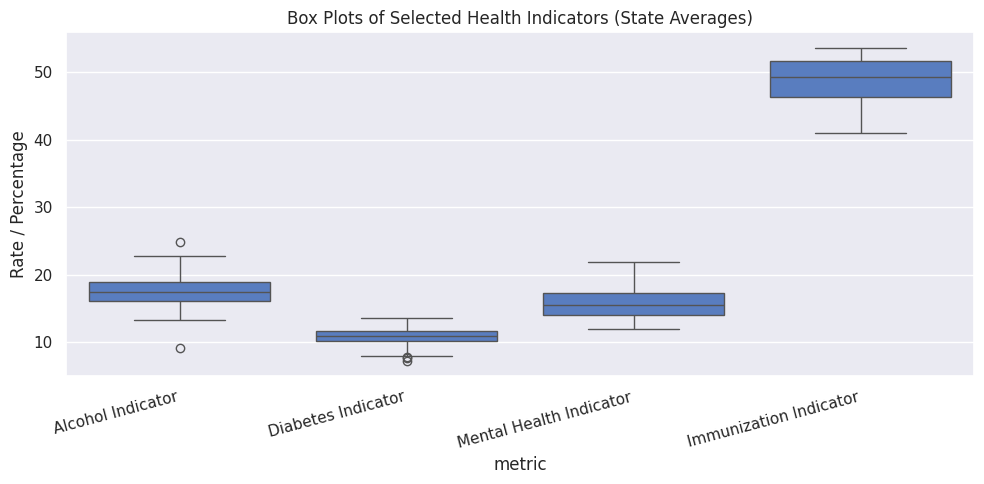

In [14]:
# Convert to Pandas for Box Plots & Scatter Plots
pdf = full_df.toPandas()
sns.set_theme(style="darkgrid", palette="muted")

# Side-by-side box plots
long_df = pdf[aliases].melt(
    value_vars=aliases,
    var_name="metric",
    value_name="rate",
).dropna(subset=["rate"])

plt.figure(figsize=(10, 5))
ax = sns.boxplot(data=long_df, x="metric", y="rate")
ax.set_xticks(range(len(aliases)))
ax.set_xticklabels(labels, rotation=15, ha="right")
plt.title("Box Plots of Selected Health Indicators (State Averages)")
plt.ylabel("Rate / Percentage")
plt.tight_layout()
plt.show()

R-squared (alcohol_rate vs diabetes_rate): 0.0558 | p-value: 9.8779e-02


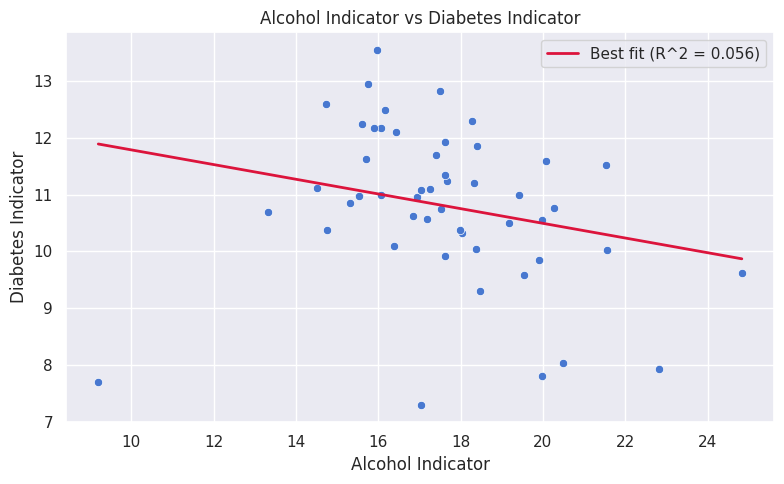

R-squared (alcohol_rate vs mental_health_rate): 0.0435 | p-value: 1.4590e-01


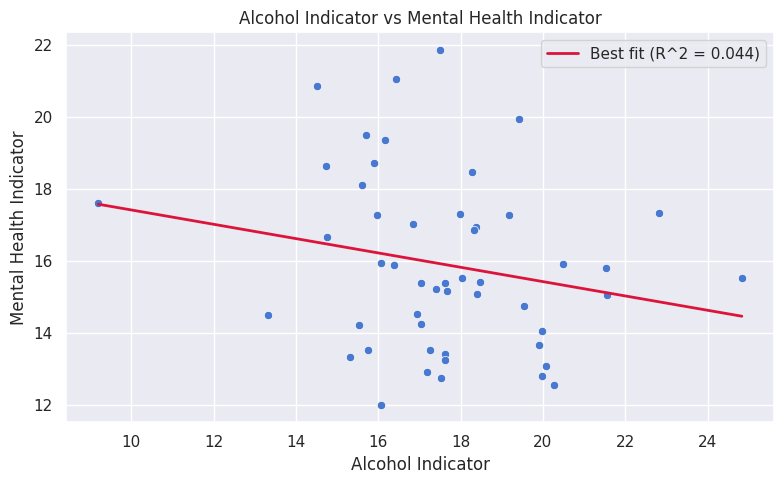

R-squared (alcohol_rate vs immunization_rate): 0.0387 | p-value: 1.7077e-01


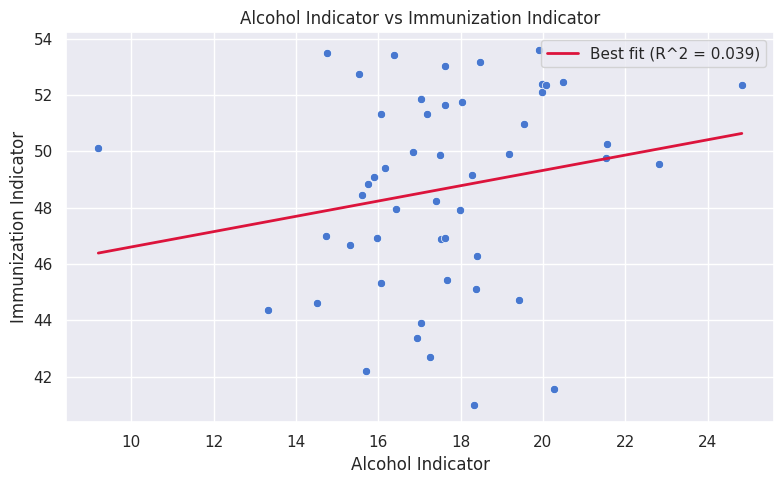

R-squared (diabetes_rate vs mental_health_rate): 0.0471 | p-value: 1.2992e-01


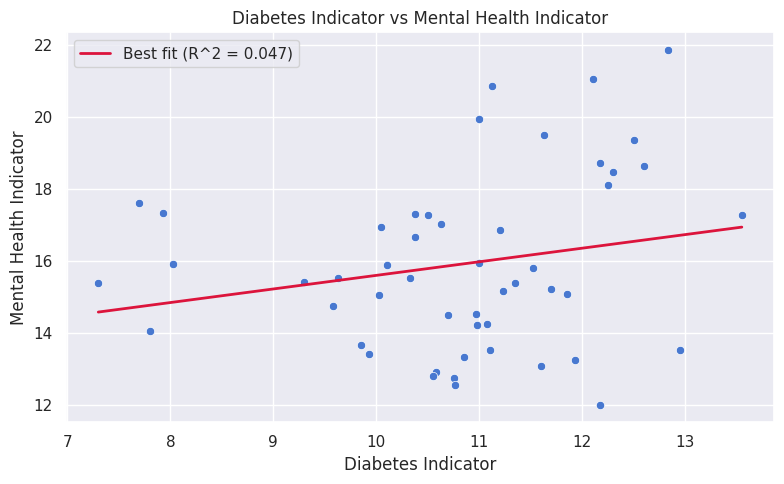

R-squared (diabetes_rate vs immunization_rate): 0.0663 | p-value: 7.1001e-02


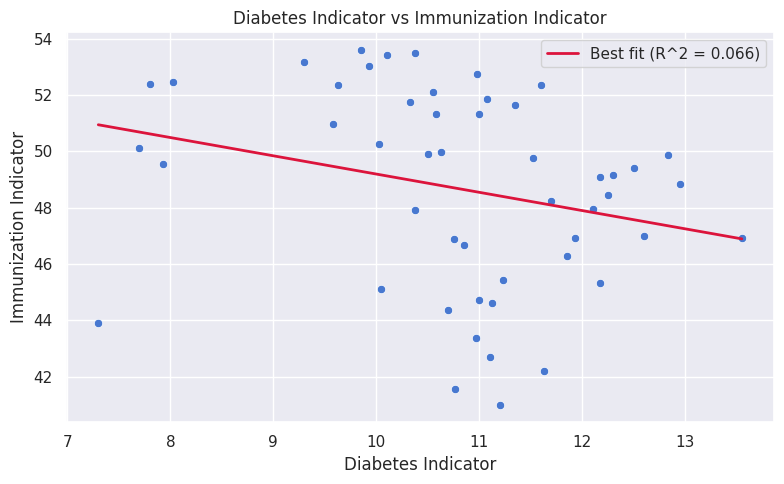

R-squared (mental_health_rate vs immunization_rate): 0.0166 | p-value: 3.7231e-01


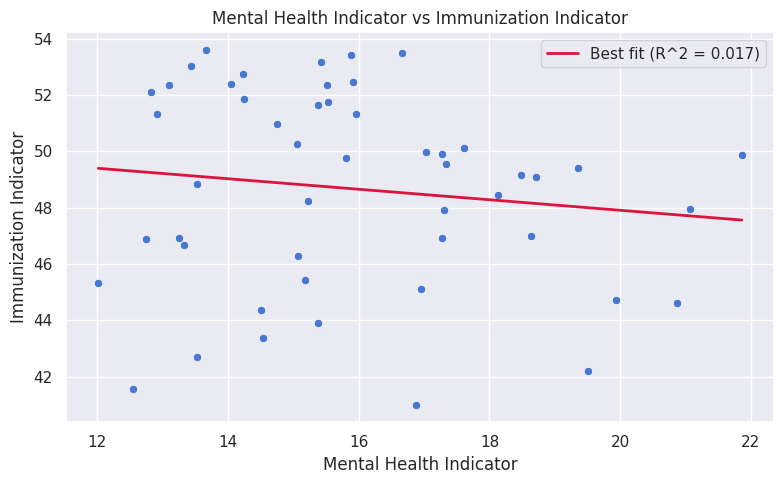

In [15]:
# Pairwise scatter plots with linear regression trendlines (6 pairs across 4 metrics)
for i in range(len(aliases)):
  for j in range(i + 1, len(aliases)):
    x_col, y_col = aliases[i], aliases[j]
    x_lbl, y_lbl = labels[i], labels[j]
    pair_df = pdf[[x_col, y_col]].dropna()
    if len(pair_df) < 2:
      continue

    res = stats.linregress(pair_df[x_col], pair_df[y_col])
    r_squared = res.rvalue**2
    x_line = np.linspace(pair_df[x_col].min(), pair_df[x_col].max(), 200)
    y_line = res.slope * x_line + res.intercept

    print(f"R-squared ({x_col} vs {y_col}): {r_squared:.4f} | p-value: {res.pvalue:.4e}")

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=pair_df, x=x_col, y=y_col)
    plt.plot(
        x_line,
        y_line,
        color="crimson",
        linewidth=2,
        label=f"Best fit (R^2 = {r_squared:.3f})",
    )
    plt.title(f"{x_lbl} vs {y_lbl}")
    plt.xlabel(x_lbl)
    plt.ylabel(y_lbl)
    plt.legend()
    plt.tight_layout()
    plt.show()